In [4]:
import numpy as np
from matplotlib import pyplot as plt
import imutils
import ipywidgets as widgets
from IPython.display import display, clear_output,Image
from skimage import data
import glob
import open3d as o3d
import copy
from mpl_toolkits.mplot3d import Axes3D
from math import *
from scipy import ndimage, signal
import sklearn as sk
import pandas as pd
import time
import datetime as dt
import ssl
from tqdm import tqdm
import cv2
from Final_Functions import load_and_undistort_images, CalibrateStereoCamera, robot_masking_MOG2
calibration = np.load("calibration_maps.npz")
Q = calibration["Q"]
fps=30

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# Working functions

In [5]:
def filter_robot_positions_jerk(
    robot_positions,
    dt,
    measurement_std,
    jerk_std,
    initial_velocity_std,
    initial_acceleration_std
):
    """
    parameters:
    - robot_positions: List of 3D positions (x, y, z) of the robot over time.
    - dt: Time step between measurements.
    - measurement_std: Standard deviation of the measurement noise.
    - jerk_std: Standard deviation of the jerk (third derivative of position).
    - initial_velocity_std: Standard deviation of the initial velocity estimate.
    - initial_acceleration_std: Standard deviation of the initial acceleration estimate.

    Output:
    - filtered: List of filtered 3D positions (x, y, z) of the robot over time, after applying the Kalman filter with jerk modeling.

    """

    measurements = np.asarray(robot_positions, dtype=float)
    filtered = np.full_like(measurements, np.nan)

    I = np.eye(3)
    kf = cv2.KalmanFilter(9, 3, 0, cv2.CV_64F)

    F = np.eye(9)
    F[0:3, 3:6] = dt * I
    F[0:3, 6:9] = 0.5 * dt**2 * I
    F[3:6, 6:9] = dt * I
    kf.transitionMatrix = F

    # Measurements still contain position only: x, y, z.
    H = np.zeros((3, 9))
    H[:, :3] = I
    kf.measurementMatrix = H

    # Measurement uncertainty.
    R = measurement_std**2 * np.eye(3)
    kf.measurementNoiseCov = R  

    G = np.vstack([
        (dt**3 / 6) * I,
        (dt**2 / 2) * I,
        dt * I,
    ])

    kf.processNoiseCov = jerk_std**2 * (G @ G.T)

    initialized = False

    for i, position in enumerate(measurements):
        valid = np.isfinite(position).all()

        if not initialized:
            if not valid:
                continue

            kf.statePost = np.concatenate([
                position, np.zeros(6)
            ]).reshape(9, 1)

            kf.errorCovPost = np.diag(
                [measurement_std**2] * 3
                + [initial_velocity_std**2] * 3
                + [initial_acceleration_std**2] * 3
            )

            filtered[i] = position
            initialized = True
            continue

        prediction = kf.predict()

        if valid:
            estimate = kf.correct(position.reshape(3, 1))
        else:
            estimate = prediction

        filtered[i] = estimate[:3, 0]

    return filtered

In [6]:
def create_stereo_matchers(min_disparity=0, num_disparities=5*16, block_size=3):
    left_matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        # Start searching at disparity 0, so far points can still match.
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8*block_size**2,
        P2=32*block_size**2,
        disp12MaxDiff=1,
        # Drop a pixel when the left-right and right-left disparities differ by more than 1.
        preFilterCap=31,
        # Clip the image gradient so bright spots do not dominate the match cost.
        uniquenessRatio=20,
        # Keep a match only when it beats the second-best cost by xx percent.
        speckleWindowSize=80,
        # Remove connected disparity blobs smaller than 80 pixels.
        speckleRange=2,
        # Pixels in one blob may differ by at most 2 disparity levels.
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
        # Match along horizontal, vertical, and diagonal paths.
    )
    wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
    wls.setLambda(2000)
    wls.setSigmaColor(0.8)
    right_matcher = cv2.ximgproc.createRightMatcher(left_matcher)

    return left_matcher, right_matcher, wls

In [7]:

def calculate_disparity_map(left_matcher, right_matcher, wls, left_image_gray, right_image_gray,test=False):

    disp_left = left_matcher.compute(left_image_gray, right_image_gray)
    disp_right = right_matcher.compute(right_image_gray, left_image_gray)

    # Spread reliable disparity into flat pixels, but stop at a color edge
    disparity_map = wls.filter(disp_left, left_image_gray, None, disp_right).astype(np.float32) / 16
    
    # Invalid pixels are -2048. Keep them out of the color scale.
    disparity_map[disparity_map < 0] = np.nan

    ### TEMP ###
    raw_disparity = disp_left.astype(np.float32) / 16.0
    filtered_disparity = (
        wls.filter(disp_left, left_image_gray, None, disp_right)
        .astype(np.float32) / 16.0
    )
    confidence = wls.getConfidenceMap()
    ### TEMP END ### 
    if test:
        return disparity_map, raw_disparity , confidence
    return disparity_map

In [8]:
def point_cloud_from_disparity(disparity_map, left_image, Q, min_disparity=3, ):   

    points_3D = cv2.reprojectImageTo3D(disparity_map, Q)

    mask = ((disparity_map > min_disparity) & np.isfinite(points_3D).all(axis=2))

    points = points_3D[mask]
    colors = left_image[mask] / 255.0

    pcd = o3d.geometry.PointCloud()

    pcd.points = o3d.utility.Vector3dVector(points)
    pcd.colors = o3d.utility.Vector3dVector(colors)
    
    pcd, ind = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)

    return pcd

In [13]:
def reconstruct_robot_trajectory(left_images, left_images_gray, right_images_gray, foreground_masks, left_matcher, right_matcher, wls, Q):
    """Return robot point clouds and centroid positions for all frames."""

    robot_pcds = []
    robot_positions = []

    frames = zip(left_images, left_images_gray, right_images_gray, foreground_masks, strict=True)

    for left_image, left_gray, right_gray, foreground_mask in frames:
        disparity_map = calculate_disparity_map(
            left_matcher, right_matcher, wls, left_gray, right_gray
        )

        # Preserve pixel coordinates while excluding the background.
        robot_disparity = disparity_map.copy()
        robot_disparity[foreground_mask <= 0] = np.nan

        robot_pcd = point_cloud_from_disparity(
            robot_disparity, left_image, Q
        )
        robot_pcds.append(robot_pcd)

        points = np.asarray(robot_pcd.points)
        center = (
            points.mean(axis=0)
            if len(points) > 0
            else np.full(3, np.nan)
        )
        robot_positions.append(center)

    return robot_pcds, np.asarray(robot_positions)

In [9]:
def reconstruct_robot_trajectory(left_images, left_images_gray, right_images_gray, foreground_masks, left_matcher, right_matcher, wls, Q, reference_frame=0):
    """Return point clouds and an SIFT-tracked 3D robot center for every frame.

    reference_frame must show the whole robot; its point-cloud centroid anchors
    the center, which is propagated by robust rigid transforms from SIFT matches.
    """
    frame_count = len(left_images)
    if not 0 <= reference_frame < frame_count:
        raise ValueError("reference_frame must identify a frame in the image sequence.")

    robot_pcds = []
    feature_descriptors = []
    feature_points_3d = []
    sift = cv2.SIFT_create()

    frames = zip(left_images, left_images_gray, right_images_gray, foreground_masks, strict=True)
    for left_image, left_gray, right_gray, foreground_mask in frames:
        disparity_map = calculate_disparity_map(
            left_matcher, right_matcher, wls, left_gray, right_gray
        )
        robot_disparity = disparity_map.copy()
        robot_disparity[foreground_mask <= 0] = np.nan
        robot_pcds.append(point_cloud_from_disparity(robot_disparity, left_image, Q))

        points_3d = cv2.reprojectImageTo3D(disparity_map, Q)
        keypoints, descriptors = sift.detectAndCompute(left_gray, foreground_mask)
        if descriptors is None:
            feature_descriptors.append(np.empty((0, 128), dtype=np.float32))
            feature_points_3d.append(np.empty((0, 3), dtype=np.float32))
            continue

        pixels = np.rint([keypoint.pt for keypoint in keypoints]).astype(int)
        x = np.clip(pixels[:, 0], 0, disparity_map.shape[1] - 1)
        y = np.clip(pixels[:, 1], 0, disparity_map.shape[0] - 1)
        points = points_3d[y, x]
        valid = (disparity_map[y, x] > 3) & np.isfinite(points).all(axis=1)
        feature_descriptors.append(descriptors[valid])
        feature_points_3d.append(points[valid])

    anchor_points = np.asarray(robot_pcds[reference_frame].points)
    if len(anchor_points) == 0:
        raise ValueError("The reference frame has no valid robot points; choose a fully visible frame with a valid mask.")
    positions = np.full((frame_count, 3), np.nan, dtype=float)
    positions[reference_frame] = anchor_points.mean(axis=0)

    matcher = cv2.BFMatcher(cv2.NORM_L2)

    def fit_rigid_transform(source, target):
        source_mean = source.mean(axis=0)
        target_mean = target.mean(axis=0)
        covariance = (source - source_mean).T @ (target - target_mean)
        u, _, vt = np.linalg.svd(covariance)
        rotation = vt.T @ u.T
        if np.linalg.det(rotation) < 0:
            vt[-1] *= -1
            rotation = vt.T @ u.T
        return rotation, target_mean - rotation @ source_mean

    def estimate_rigid_motion(source, target, frame_index):
        if len(source) < 3:
            raise RuntimeError(f"Only {len(source)} valid SIFT matches between frames {frame_index} and {frame_index + 1}; cannot track the robot center.")

        radius = np.median(np.linalg.norm(source - np.median(source, axis=0), axis=1))
        threshold = max(0.01, 0.05 * radius)
        rng = np.random.default_rng(frame_index)
        best_inliers = np.zeros(len(source), dtype=bool)
        for _ in range(min(200, max(50, len(source) * 5))):
            sample = rng.choice(len(source), size=3, replace=False)
            rotation, translation = fit_rigid_transform(source[sample], target[sample])
            residuals = np.linalg.norm((rotation @ source.T).T + translation - target, axis=1)
            inliers = residuals <= threshold
            if inliers.sum() > best_inliers.sum():
                best_inliers = inliers

        if best_inliers.sum() < 3:
            raise RuntimeError(f"Could not estimate reliable SIFT motion between frames {frame_index} and {frame_index + 1}.")
        return fit_rigid_transform(source[best_inliers], target[best_inliers])

    motions = []
    for frame_index in range(frame_count - 1):
        matches = matcher.knnMatch(feature_descriptors[frame_index], feature_descriptors[frame_index + 1], k=2)
        good_matches = [
            first for pair in matches if len(pair) == 2
            for first, second in [pair]
            if first.distance < 0.75 * second.distance
        ]
        source = np.asarray([feature_points_3d[frame_index][match.queryIdx] for match in good_matches])
        target = np.asarray([feature_points_3d[frame_index + 1][match.trainIdx] for match in good_matches])
        motions.append(estimate_rigid_motion(source, target, frame_index))

    for frame_index in range(reference_frame, frame_count - 1):
        rotation, translation = motions[frame_index]
        positions[frame_index + 1] = rotation @ positions[frame_index] + translation
    for frame_index in range(reference_frame - 1, -1, -1):
        rotation, translation = motions[frame_index]
        positions[frame_index] = rotation.T @ (positions[frame_index + 1] - translation)

    return robot_pcds, positions

In [10]:
def visualize_robot_trajectory(scene_pcd, robot_positions):
    """Show robot centroids and trajectory within the reconstructed scene."""
    positions = np.asarray(robot_positions, dtype=float)
    valid = np.isfinite(positions).all(axis=1)

    if not valid.any():
        raise ValueError("No valid robot positions to visualize.")

    # Map original frame indices to the filtered point indices.
    point_indices = np.full(len(positions), -1, dtype=int)
    point_indices[valid] = np.arange(valid.sum())

    # Connect consecutive frames only, preserving gaps in tracking.
    consecutive = np.flatnonzero(valid[:-1] & valid[1:])
    lines = np.column_stack((
        point_indices[consecutive],
        point_indices[consecutive + 1],
    ))

    trajectory_points = positions[valid]

    centroids = o3d.geometry.PointCloud()
    centroids.points = o3d.utility.Vector3dVector(trajectory_points)
    centroids.paint_uniform_color([1.0, 0.0, 0.0])

    trajectory = o3d.geometry.LineSet()
    trajectory.points = o3d.utility.Vector3dVector(trajectory_points)
    trajectory.lines = o3d.utility.Vector2iVector(lines)
    trajectory.paint_uniform_color([1.0, 0.6, 0.0])

    o3d.visualization.draw_geometries(
        [scene_pcd, centroids, trajectory],
        window_name="Robot trajectory",
        width=1280,
        height=720,
    )

# Working area

In [ ]:
calibration_success = CalibrateStereoCamera()
display(calibration_success)

720 1280


True

In [ ]:
# undistL, undistR, undistLg, undistRg = load_and_undistort_images('1_no_obstacle')
undistL, undistR, undistLg, undistRg = load_and_undistort_images('4_circle')

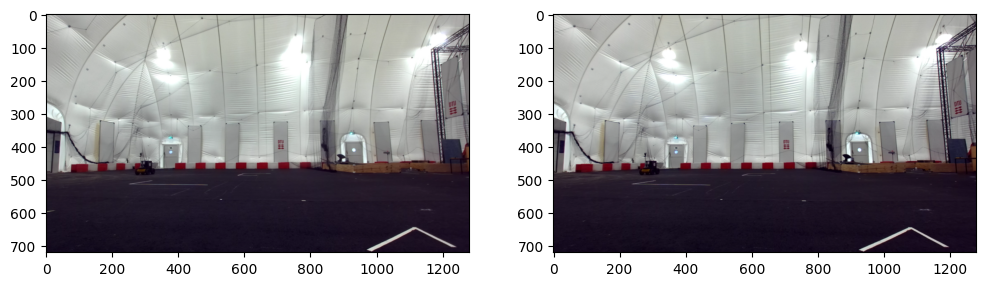

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(undistL[100])
ax[1].imshow(undistR[100])

### optical flow to track 

In [73]:
undistL, undistR, undistLg, undistRg = load_and_undistort_images('2_obstacle')

In [11]:
def detect_robot_dense_optical(undistLg, start_frame=0, end_frame=None):
    '''
    Detects the robot in a sequence of undistorted grayscale images
    by computing optical flow and generating masks based on the magnitude of the flow.

    parameters:
    - undistLg: list; undistorted and rectified images from the left camera in a stereo camera
    - start_frame: int; positive start frame number
    - end_frame: ing; end_frame number

    returns:
    - masks: List of masks only indicating the detected robot regions in each frame.
    '''
    
    flows = []
    magnitudes = []
    shape = undistLg[0].shape
    ROIy = [325, 600]
    ROIx = [0, 1280]

    foreground_masks = []

    threshold = 3.0
    open_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))

    # loop through the undistorted grayscale images to compute optical flow
    if end_frame == None:
        end_frame = len(undistLg) - 1
    elif end_frame > (len(undistLg) - 1):
        print("end frame out of bounds")
        return 

    for i in range(start_frame, end_frame):
        gray1 = undistLg[i][ROIy[0]:ROIy[1], ROIx[0]:ROIx[1]]
        gray2 = undistLg[i + 1][ROIy[0]:ROIy[1], ROIx[0]:ROIx[1]]

        # get Optical flow
        flow = cv2.calcOpticalFlowFarneback(
            gray1, gray2,
            None,
            0.5, 3, 15, 3, 5, 1.5, 0
        )

        # convert flow to polar coordinates to get magnitude and angle
        mag,theta = cv2.cartToPolar(flow[..., 0], flow[..., 1])

        # flows.append(flow)
        # magnitudes.append(mag)
        mask = np.zeros(shape, dtype=np.uint8)
        mask[ROIy[0]:ROIy[1], ROIx[0]:ROIx[1]] = (mag > threshold).astype(np.uint8) * 255

         # do opening and closing to remove noise and fill gaps in the masks
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, open_kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_kernel, iterations=3)

        num_labels, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(mask)
        )

        if num_labels > 1:
            largest = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
            )
            mask = np.uint8(labels == largest) * 255
        
        foreground_masks.append(mask)
    # Copy the last mask to match number of images 
    foreground_masks.append(mask)
        
    return foreground_masks

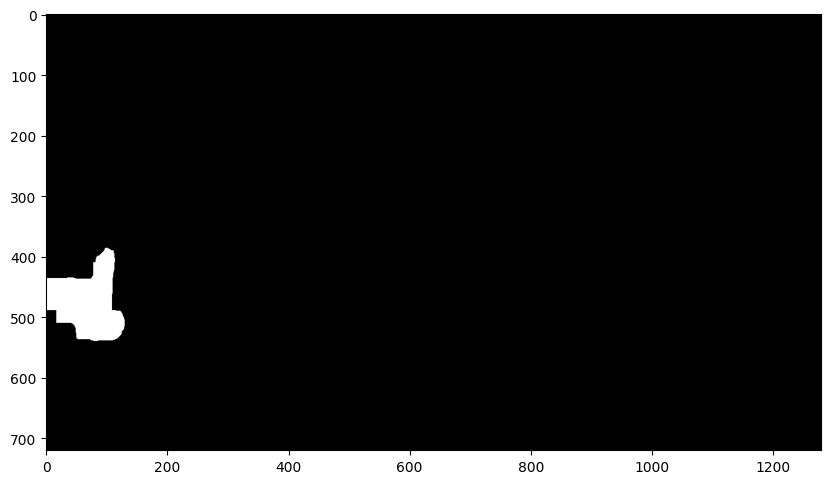

In [91]:
Masks = detect_robot_dense_optical(undistL, undistLg, undistR, undistRg, 100, 101)
for i in range(len(Masks)):
    plt.figure(figsize=(10, 6))
    plt.imshow(Masks[i], cmap='gray')

# Estimate robot center

In [ ]:
def KalmanPredict(x, P, F, u, Q):
    """
    Kalman prediction step — project the state forward one timestep using
    the motion model F and control input u.

    Steps:
      x = F·x + u    Apply physics: advance position by current velocity
      P = F·P·Fᵀ     Propagate uncertainty (grows because we're extrapolating)

    Note: a full implementation would add process noise Q here (P = F·P·Fᵀ + Q),
    but Q=0 is assumed (perfect motion model).
    """
    x = F@x + u          # Predict next state
    P = F@P@ F.T +Q # Predict next covariance
    return [x, P]

def KalmanUpdate(x, P, Z, H, R):
    """
    Kalman measurement update — fuse a new observation Z into the current
    state estimate x and covariance P.

    Steps:
      y = z - H·x        Innovation: how far off was our prediction?
      S = H·P·Hᵀ + R     Innovation covariance (uncertainty of the prediction in measurement space)
      K = P·Hᵀ·S⁻¹       Kalman gain: how much to trust the measurement vs. the model
      x = x + K·y        Nudge state toward the measurement, weighted by K
      P = (I - K·H)·P    Reduce uncertainty — we've gained information
    """
    y = Z - H @ x                          # Innovation
    S = H @ P @ H.T + R             # Innovation covariance
    K = P @ H.T @ np.linalg.pinv(S) # Kalman gain
    x = x + K @ y                          # State update
    P = (I - K @ H) @ P             # Covariance update
    return [x, P]

In [ ]:
def filter_robot_positions_jerk(
    robot_positions,
    dt,
    measurement_std,
    jerk_std,
    initial_velocity_std,
    initial_acceleration_std
):

    measurements = np.asarray(robot_positions, dtype=float)
    filtered = np.full_like(measurements, np.nan)

    I = np.eye(3)
    kf = cv2.KalmanFilter(9, 3, 0, cv2.CV_64F)

    F = np.eye(9)
    F[0:3, 3:6] = dt * I
    F[0:3, 6:9] = 0.5 * dt**2 * I
    F[3:6, 6:9] = dt * I
    kf.transitionMatrix = F

    # Measurements still contain position only: x, y, z.
    H = np.zeros((3, 9))
    H[:, :3] = I
    kf.measurementMatrix = H

    # Measurement uncertainty.
    R = measurement_std**2 * np.eye(3)
    kf.measurementNoiseCov = R  

    G = np.vstack([
        (dt**3 / 6) * I,
        (dt**2 / 2) * I,
        dt * I,
    ])

    kf.processNoiseCov = jerk_std**2 * (G @ G.T)

    initialized = False

    for i, position in enumerate(measurements):
        valid = np.isfinite(position).all()

        if not initialized:
            if not valid:
                continue

            kf.statePost = np.concatenate([
                position, np.zeros(6)
            ]).reshape(9, 1)

            kf.errorCovPost = np.diag(
                [measurement_std**2] * 3
                + [initial_velocity_std**2] * 3
                + [initial_acceleration_std**2] * 3
            )

            filtered[i] = position
            initialized = True
            continue

        prediction = kf.predict()

        if valid:
            estimate = kf.correct(position.reshape(3, 1))
        else:
            estimate = prediction

        filtered[i] = estimate[:3, 0]

    return filtered

In [97]:
def pipeline(left_images,right_images,left_images_gray,right_images_gray,fps):    
### pipeline 
    # Construct stereo matchers
    left_matcher, right_matcher, wls = create_stereo_matchers()

    # Disparity map calculation
    disparity_map = calculate_disparity_map(left_matcher, right_matcher, wls, left_images_gray[0], right_images_gray[0])

    # Construct the scene point cloud from disparity map
    scene_pcd = point_cloud_from_disparity(disparity_map, left_images[0], Q)

    # Construct robot foreground masks.
    # robot_foreground_masks = robot_masking_MOG2(left_images)
    robot_foreground_masks = detect_robot_dense_optical(left_images_gray)

    # Reconstruct the robot and its trajectory.
    robot_pcds, robot_positions = reconstruct_robot_trajectory(
        left_images,
        left_images_gray,
        right_images_gray,
        robot_foreground_masks,
        left_matcher,
        right_matcher,
        wls,
        Q,
    )

    filtered_positions = filter_robot_positions_jerk(
        robot_positions,
        dt=1 / fps,                         # Actual frame interval in seconds
        measurement_std=0.5,
        jerk_std = 5.0,
        initial_velocity_std = 10,
        initial_acceleration_std = 10.0,
    )

    return scene_pcd, robot_positions, filtered_positions

# Pipeline

In [12]:
left_images, right_images, left_images_gray, right_images_gray = load_and_undistort_images('1_no_obstacle')

In [13]:
left_matcher, right_matcher, wls = create_stereo_matchers()

In [14]:
# Disparity map calculation
disparity_map = calculate_disparity_map(left_matcher, right_matcher, wls, left_images_gray[0], right_images_gray[0])

In [15]:
# Construct the scene point cloud from disparity map
scene_pcd = point_cloud_from_disparity(disparity_map, left_images[0], Q)

In [16]:
# Construct robot foreground masks.
# robot_foreground_masks = robot_masking_MOG2(left_images)
robot_foreground_masks = detect_robot_dense_optical(left_images_gray)

In [ ]:
robot_center

In [18]:
# Reconstruct the robot and its trajectory.
robot_pcds, robot_positions = reconstruct_robot_trajectory(
    left_images,
    left_images_gray,
    right_images_gray,
    robot_foreground_masks,
    left_matcher,
    right_matcher,
    wls,
    Q,
    100,
)

RuntimeError: Only 0 valid SIFT matches between frames 0 and 1; cannot track the robot center.

In [110]:

filtered_positions = filter_robot_positions_jerk(
    robot_positions,
    dt=1 / fps,                         # Actual frame interval in seconds
    measurement_std=0.5,
    jerk_std = 5.0,
    initial_velocity_std = 10,
    initial_acceleration_std = 10.0,
)

In [112]:
visualize_robot_trajectory(pcd, filtered_positions)